# Double Pendulum: Symbolic Derivation and ODE Simulation

This notebook is the executable companion to Chapter 4 of the book plan. It derives the equations from kinematics and energy with SymPy, extracts the mass matrix and remaining force vector, verifies the symbolic result, then integrates the unforced motion and checks energy behavior.

## Model and conventions

Two point masses $m_1$ and $m_2$ are connected by massless rigid rods of lengths $l_1$ and $l_2$. The first pivot is fixed. Angles $\theta_1$ and $\theta_2$ are **absolute angles measured from the downward vertical**, and world $y$ is positive upward. Rod and pivot friction are neglected; the generalized torques $\tau_1,\tau_2$ are retained symbolically and set to zero for the conservative simulation.

The coordinates are $q=[\theta_1,\theta_2]^T$, with generalized velocities $\dot q=[\dot\theta_1,\dot\theta_2]^T$. The angle convention determines the signs in the position, gravity, and torque terms, so keep it fixed throughout.

In [21]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display
from pathlib import Path

sp.init_printing()
np.set_printoptions(precision=5, suppress=True)

# Support execution with the kernel working directory at either the project root or notebooks/.
project_root = Path.cwd()
if not (project_root / "figures").is_dir() and (project_root.parent / "figures").is_dir():
    project_root = project_root.parent
figures_directory = project_root / "figures"
figures_directory.mkdir(parents=True, exist_ok=True)

print(f"NumPy {np.__version__}")
print(f"SymPy {sp.__version__}")
print(f"Figure output directory: {figures_directory.resolve()}")

NumPy 2.5.3
SymPy 1.14.0
Figure output directory: C:\Users\Mourad\Desktop\multybody systems\figures


## 1. Kinematics from the chosen coordinates

With angles measured clockwise from downward vertical, the mass positions are

$$
\begin{aligned}
x_1 &= l_1\sin\theta_1, & y_1 &= -l_1\cos\theta_1,\\
x_2 &= x_1+l_2\sin\theta_2, & y_2 &= y_1-l_2\cos\theta_2.
\end{aligned}
$$

Differentiate these positions with respect to time to obtain Cartesian velocities. The code below first derives the position and velocity expressions symbolically; those expressions then define the kinetic and potential energy.

Mass positions [x1, y1, x2, y2]:


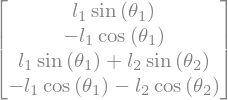

Mass velocities [vx1, vy1, vx2, vy2]:


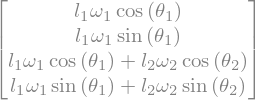

Kinetic energy T:


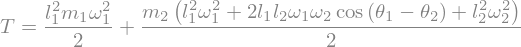

Potential energy V:


Lagrangian L = T - V:


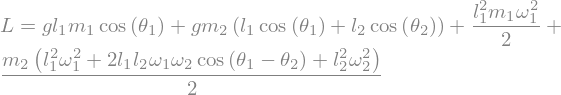

In [22]:
# Physical parameters are kept symbolic throughout the derivation.
m1, m2, l1, l2, g = sp.symbols("m_1 m_2 l_1 l_2 g", positive=True, finite=True)
theta1, theta2 = sp.symbols("theta_1 theta_2", real=True)
omega1, omega2 = sp.symbols("omega_1 omega_2", real=True)
q = sp.Matrix([theta1, theta2])
qdot = sp.Matrix([omega1, omega2])

x1 = l1 * sp.sin(theta1)
y1 = -l1 * sp.cos(theta1)
x2 = x1 + l2 * sp.sin(theta2)
y2 = y1 - l2 * sp.cos(theta2)
position = sp.Matrix([x1, y1, x2, y2])
velocity = position.jacobian(q) * qdot
vx1, vy1, vx2, vy2 = velocity

kinetic_energy = sp.Rational(1, 2) * m1 * (vx1**2 + vy1**2) + sp.Rational(1, 2) * m2 * (vx2**2 + vy2**2)
potential_energy = m1 * g * y1 + m2 * g * y2
lagrangian = sp.trigsimp(kinetic_energy - potential_energy)

print("Mass positions [x1, y1, x2, y2]:")
display(position)
print("Mass velocities [vx1, vy1, vx2, vy2]:")
display(velocity)
print("Kinetic energy T:")
display(sp.Eq(sp.Symbol("T"), sp.trigsimp(kinetic_energy)))
print("Potential energy V:")
display(sp.Eq(sp.Symbol("V"), sp.trigsimp(potential_energy)))
print("Lagrangian L = T - V:")
display(sp.Eq(sp.Symbol("L"), lagrangian))

## 2. Euler-Lagrange equations and symbolic extraction

For each generalized coordinate, use

$$\frac{d}{dt}\left(\frac{\partial L}{\partial \dot q_i}\right)-\frac{\partial L}{\partial q_i}=\tau_i.$$

The total time derivative is evaluated by the chain rule, treating positions, velocities, and accelerations as independent symbolic variables during differentiation. The residual is affine in $\ddot q$, so its Jacobian with respect to acceleration is the mass matrix. The remainder is $h(q,\dot q)$, containing velocity-coupling and gravity terms.

Euler-Lagrange equations, written as residuals equal to zero:


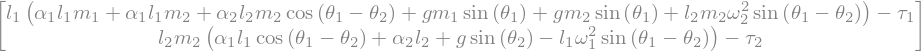

Mass matrix M(q):


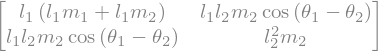

Remaining vector h(q, qdot):


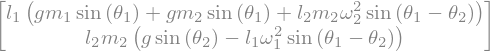

Symbolic decomposition residual:


In [23]:
alpha1, alpha2 = sp.symbols("alpha_1 alpha_2", real=True)
tau1, tau2 = sp.symbols("tau_1 tau_2", real=True)
qddot = sp.Matrix([alpha1, alpha2])
tau = sp.Matrix([tau1, tau2])


def total_time_derivative(expression):
    return sum(
        sp.diff(expression, coordinate) * speed
        + sp.diff(expression, speed) * acceleration
        for coordinate, speed, acceleration in zip(q, qdot, qddot)
    )


momentum = sp.Matrix([sp.diff(lagrangian, speed) for speed in qdot])
momentum_rate = momentum.applyfunc(total_time_derivative)
euler_lagrange_left = sp.Matrix([
    momentum_rate[index] - sp.diff(lagrangian, q[index])
    for index in range(len(q))
]).applyfunc(sp.trigsimp)

mass_matrix = euler_lagrange_left.jacobian(qddot).applyfunc(sp.trigsimp)
h_vector = (euler_lagrange_left - mass_matrix * qddot).applyfunc(sp.trigsimp)
symbolic_decomposition_residual = (
    euler_lagrange_left - mass_matrix * qddot - h_vector
).applyfunc(sp.trigsimp)
assert all(sp.simplify(entry) == 0 for entry in symbolic_decomposition_residual)

print("Euler-Lagrange equations, written as residuals equal to zero:")
display(euler_lagrange_left - tau)
print("Mass matrix M(q):")
display(mass_matrix)
print("Remaining vector h(q, qdot):")
display(h_vector)
print("Symbolic decomposition residual:")
display(symbolic_decomposition_residual)

## 3. Check the standard matrix form

Let $\delta=\theta_1-\theta_2$. The equations can be written

$$M(q)\ddot q+h(q,\dot q)=\tau,$$

where the off-diagonal inertia terms arise from coupling between the rods. We compare SymPy's result with the hand-readable form used in the book. The determinant check also confirms that $M$ is nonsingular for positive masses and lengths.

In [24]:
delta = theta1 - theta2
mass_expected = sp.Matrix([
    [(m1 + m2) * l1**2, m2 * l1 * l2 * sp.cos(delta)],
    [m2 * l1 * l2 * sp.cos(delta), m2 * l2**2],
])
h_expected = sp.Matrix([
    m2 * l1 * l2 * sp.sin(delta) * omega2**2
    + (m1 + m2) * g * l1 * sp.sin(theta1),
    -m2 * l1 * l2 * sp.sin(delta) * omega1**2
    + m2 * g * l2 * sp.sin(theta2),
])

simplify_zero = lambda value: sp.simplify(sp.trigsimp(value))
assert all(simplify_zero(value) == 0 for value in mass_matrix - mass_expected)
assert all(simplify_zero(value) == 0 for value in h_vector - h_expected)
determinant = sp.factor(mass_matrix.det())
determinant_expected = m2 * l1**2 * l2**2 * (m1 + m2 * sp.sin(delta)**2)
assert simplify_zero(determinant - determinant_expected) == 0

print("The extracted expressions match the standard equations.")
print("det(M) =")
display(determinant)

The extracted expressions match the standard equations.
det(M) =


## 4. Prepare the first-order ODE

The symbolic equations are

$$M(q)\ddot q+h(q,\dot q)=\tau.$$

For the unforced example, $\tau=[0,0]^T$. At each right-hand-side evaluation, solve the two-by-two linear system $M(q)\ddot q=-h(q,\dot q)$; do not explicitly form $M^{-1}$. Define the first-order state as

$$y=[\theta_1,\theta_2,\omega_1,\omega_2]^T,\qquad
\dot y=[\omega_1,\omega_2,\alpha_1,\alpha_2]^T.$$

The next cell substitutes numerical parameters, compiles the symbolic expressions into numerical functions, and passes this state derivative to an adaptive integrator.

In [25]:
# Illustrative SI parameters; keep these substitutions separate from the symbolic derivation.
parameters = {
    m1: 1.2,       # kg
    m2: 0.8,       # kg
    l1: 1.0,       # m
    l2: 0.8,       # m
    g: 9.81,       # m/s^2
}

mass_function = sp.lambdify(
    (theta1, theta2, m1, m2, l1, l2), mass_matrix, modules="numpy"
)
h_function = sp.lambdify(
    (theta1, theta2, omega1, omega2, m1, m2, l1, l2, g),
    h_vector,
    modules="numpy",
)
energy_function = sp.lambdify(
    (theta1, theta2, omega1, omega2, m1, m2, l1, l2, g),
    kinetic_energy + potential_energy,
    modules="numpy",
)
parameter_values = tuple(parameters[symbol] for symbol in (m1, m2, l1, l2))
parameter_values_with_gravity = (*parameter_values, parameters[g])

def state_derivative(time, state):
    angle_1, angle_2, speed_1, speed_2 = state
    matrix_value = np.asarray(
        mass_function(angle_1, angle_2, *parameter_values), dtype=float
    )
    force_terms = np.asarray(
        h_function(angle_1, angle_2, speed_1, speed_2, *parameter_values_with_gravity),
        dtype=float,
    ).reshape(2)
    acceleration = np.linalg.solve(matrix_value, -force_terms)
    return np.array([speed_1, speed_2, acceleration[0], acceleration[1]])

simulation_duration = 10.0
output_times = np.linspace(0.0, simulation_duration, 2001)
initial_state = np.array([1.1, -0.6, 0.0, 0.0])
solution = solve_ivp(
    state_derivative,
    (0.0, simulation_duration),
    initial_state,
    t_eval=output_times,
    method="RK45",
    rtol=1e-9,
    atol=1e-11,
    max_step=0.01,
)
assert solution.success, solution.message
assert np.isclose(solution.t[-1], simulation_duration)
print(f"Integration successful: {solution.success}")
print(f"Saved states: {solution.t.size}; RHS evaluations: {solution.nfev}")

Integration successful: True
Saved states: 2001; RHS evaluations: 7334


## 5. Numerical energy check

With no applied torques and no dissipation, total mechanical energy $E=T+V$ should be constant in the continuous model. The baseline numerical run introduces a small energy error, which is reported below. Section 6 repeats the run with tighter tolerances and a smaller maximum step to check sensitivity; neither energy agreement nor this single refinement proves physical validity or bounds long-time phase error.

In [ ]:
energy_values = np.array([
    energy_function(*solution.y[:, index], *parameter_values_with_gravity)
    for index in range(solution.t.size)
], dtype=float)
initial_energy = energy_values[0]
energy_error = energy_values - initial_energy
maximum_absolute_energy_error = np.max(np.abs(energy_error))
energy_scale = max(abs(initial_energy), 1.0)
maximum_relative_energy_error = maximum_absolute_energy_error / energy_scale

print(f"Initial total energy: {initial_energy:.12g} J")
print(f"Maximum absolute energy error: {maximum_absolute_energy_error:.3e} J")
print(f"Maximum relative energy error: {maximum_relative_energy_error:.3e}")
assert np.all(np.isfinite(energy_values))
assert maximum_relative_energy_error < 1e-6

Initial total energy: -14.081343027 J
Maximum absolute energy error: 1.320e-07 J
Maximum relative energy error: 9.373e-09


## 6. Tolerance and step-size sensitivity

Repeat the same initial-value problem with tighter local-error tolerances and half the maximum internal step. Compare the sampled state history and scaled energy error against the baseline. In this run, tightening to `rtol=1e-10`, `atol=1e-12`, and `max_step=0.005 s` used 13,136 RHS evaluations, reduced maximum scaled energy error from `9.373e-9` to `4.494e-10`, and gave a maximum sampled state difference of `4.736e-8`. This is a focused sensitivity check, not a formal convergence proof or long-time phase-error bound.

In [32]:
sensitivity_solution = solve_ivp(
    state_derivative,
    (0.0, simulation_duration),
    initial_state,
    t_eval=output_times,
    method="RK45",
    rtol=1e-10,
    atol=1e-12,
    max_step=0.005,
)
assert sensitivity_solution.success, sensitivity_solution.message
assert np.allclose(sensitivity_solution.t, solution.t)

sensitivity_energy_values = np.array([
    energy_function(*sensitivity_solution.y[:, index], *parameter_values_with_gravity)
    for index in range(sensitivity_solution.t.size)
], dtype=float)
sensitivity_energy_error = (
    np.max(np.abs(sensitivity_energy_values - sensitivity_energy_values[0]))
    / max(abs(sensitivity_energy_values[0]), 1.0)
)
maximum_state_difference = np.max(np.abs(sensitivity_solution.y - solution.y))
print(f"Sensitivity run: rtol=1e-10, atol=1e-12, max_step=0.005 s")
print(f"RHS evaluations: {sensitivity_solution.nfev}")
print(f"Maximum scaled energy error: {sensitivity_energy_error:.3e}")
print(f"Maximum state difference from baseline: {maximum_state_difference:.3e}")
assert np.isfinite(maximum_state_difference)
assert np.isfinite(sensitivity_energy_error)

Sensitivity run: rtol=1e-10, atol=1e-12, max_step=0.005 s
RHS evaluations: 13136
Maximum scaled energy error: 4.494e-10
Maximum state difference from baseline: 4.736e-08


## 6. Plot the simulated response

Plot both absolute angles and the signed, scaled energy error $(E-E_0)/\max(1\,\mathrm{J},|E_0|)$. The output sampling is for plotting; the adaptive solver chooses its own internal steps subject to the tolerance and maximum-step settings above.

Saved response and energy figure: c:\Users\Mourad\Desktop\multybody systems\figures\double_pendulum_response.png


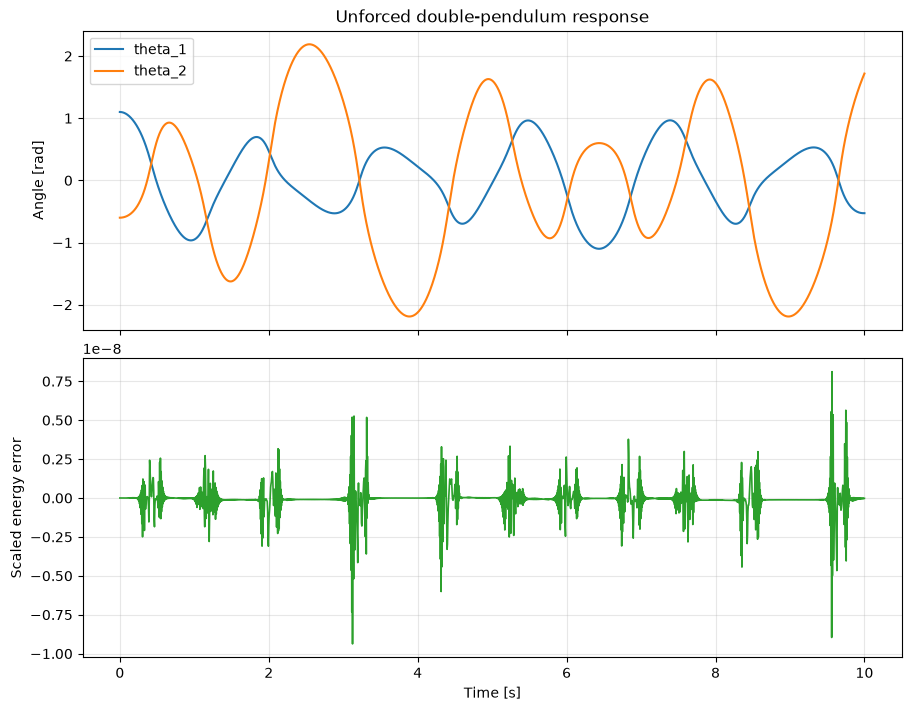

In [29]:
angle_1_history, angle_2_history = solution.y[0], solution.y[1]
figure, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, constrained_layout=True)
axes[0].plot(solution.t, angle_1_history, label="theta_1", linewidth=1.5)
axes[0].plot(solution.t, angle_2_history, label="theta_2", linewidth=1.5)
axes[0].set_ylabel("Angle [rad]")
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_title("Unforced double-pendulum response")

axes[1].plot(solution.t, energy_error / energy_scale, color="C2", linewidth=1.2)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Scaled energy error")
axes[1].grid(True, alpha=0.3)
response_figure_path = figures_directory / "double_pendulum_response.png"
figure.savefig(response_figure_path, dpi=180, bbox_inches="tight")
print(f"Saved response and energy figure: {response_figure_path}")
plt.show()

## 7. Geometry, coordinates, and parameters

The geometry panel shows the two absolute angles, rod lengths, point masses, and downward gravity direction. The notation panel separates the generalized coordinates and their rates from the fixed model parameters; the numerical parameter values shown are the SI values used for the simulation.

Saved geometry figure: c:\Users\Mourad\Desktop\multybody systems\figures\double_pendulum_geometry.png


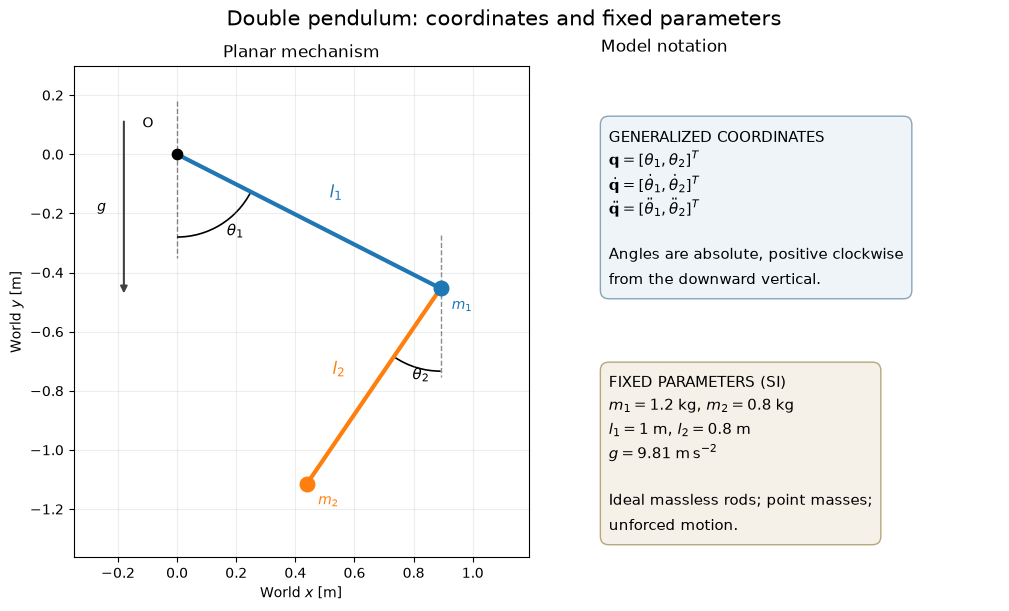

In [31]:
from matplotlib.patches import Arc

angle_1_initial, angle_2_initial = initial_state[:2]
length_1_value = parameters[l1]
length_2_value = parameters[l2]
pivot = np.array([0.0, 0.0])
mass_1_position = np.array([
    length_1_value * np.sin(angle_1_initial),
    -length_1_value * np.cos(angle_1_initial),
])
mass_2_position = mass_1_position + np.array([
    length_2_value * np.sin(angle_2_initial),
    -length_2_value * np.cos(angle_2_initial),
])

figure = plt.figure(figsize=(10, 6), constrained_layout=True)
grid = figure.add_gridspec(1, 2, width_ratios=[1.45, 1.0])
axis = figure.add_subplot(grid[0, 0])
notation_axis = figure.add_subplot(grid[0, 1])

axis.plot(
    [pivot[0], mass_1_position[0]],
    [pivot[1], mass_1_position[1]],
    color="C0",
    linewidth=3,
)
axis.plot(
    [mass_1_position[0], mass_2_position[0]],
    [mass_1_position[1], mass_2_position[1]],
    color="C1",
    linewidth=3,
)
axis.scatter(*pivot, color="black", s=55, zorder=3)
axis.scatter(*mass_1_position, color="C0", s=110, zorder=3)
axis.scatter(*mass_2_position, color="C1", s=110, zorder=3)
axis.text(pivot[0] - 0.08, pivot[1] + 0.08, "O", ha="right", va="bottom")
axis.annotate(
    r"$m_1$",
    mass_1_position,
    xytext=(8, -15),
    textcoords="offset points",
    color="C0",
    weight="bold",
)
axis.annotate(
    r"$m_2$",
    mass_2_position,
    xytext=(8, -15),
    textcoords="offset points",
    color="C1",
    weight="bold",
)

axis.plot([0.0, 0.0], [0.18, -0.35], "k--", alpha=0.45, linewidth=1)
axis.plot(
    [mass_1_position[0], mass_1_position[0]],
    [mass_1_position[1] + 0.18, mass_1_position[1] - 0.3],
    "k--",
    alpha=0.45,
    linewidth=1,
)
axis.annotate(
    "",
    xy=(-0.18, -0.48),
    xytext=(-0.18, 0.12),
    arrowprops={"arrowstyle": "-|>", "color": "0.25", "lw": 1.5},
)
axis.text(-0.24, -0.18, r"$g$", ha="right", va="center")

angle_1_degrees = np.degrees(angle_1_initial)
angle_2_degrees = np.degrees(angle_2_initial)
ray_1_degrees = angle_1_degrees - 90.0
ray_2_degrees = angle_2_degrees - 90.0
radius = 0.28
axis.add_patch(
    Arc(pivot, 2 * radius, 2 * radius, theta1=-90, theta2=ray_1_degrees,
        color="black", linewidth=1.2)
)
axis.add_patch(
    Arc(
        mass_1_position,
        2 * radius,
        2 * radius,
        theta1=min(ray_2_degrees, -90.0),
        theta2=max(ray_2_degrees, -90.0),
        color="black",
        linewidth=1.2,
    )
)
mid_1 = np.radians((-90.0 + ray_1_degrees) / 2.0)
mid_2 = np.radians((ray_2_degrees - 90.0) / 2.0)
axis.text(
    radius * 1.15 * np.cos(mid_1),
    radius * 1.15 * np.sin(mid_1),
    r"$\theta_1$",
    fontsize=11,
)
axis.text(
    mass_1_position[0] + radius * 1.15 * np.cos(mid_2),
    mass_1_position[1] + radius * 1.15 * np.sin(mid_2),
    r"$\theta_2$",
    fontsize=11,
)
midpoint_1 = 0.5 * (pivot + mass_1_position)
midpoint_2 = 0.5 * (mass_1_position + mass_2_position)
axis.text(
    midpoint_1[0] + 0.07,
    midpoint_1[1] + 0.08,
    r"$l_1$",
    color="C0",
    fontsize=12,
    weight="bold",
)
axis.text(
    midpoint_2[0] - 0.14,
    midpoint_2[1] + 0.04,
    r"$l_2$",
    color="C1",
    fontsize=12,
    weight="bold",
)
axis.set_xlim(min(-0.35, mass_2_position[0] - 0.25), max(0.45, mass_1_position[0] + 0.3))
axis.set_ylim(min(mass_2_position[1] - 0.25, -0.65), 0.3)
axis.set_aspect("equal", adjustable="box")
axis.set_xlabel(r"World $x$ [m]")
axis.set_ylabel(r"World $y$ [m]")
axis.set_title("Planar mechanism")
axis.grid(True, alpha=0.22)

notation_axis.axis("off")
notation_axis.set_title("Model notation", loc="left", pad=10)
notation_axis.text(
    0.02,
    0.88,
    "GENERALIZED COORDINATES\n"
    r"$\mathbf{q}=[\theta_1,\theta_2]^T$" "\n"
    r"$\dot{\mathbf{q}}=[\dot\theta_1,\dot\theta_2]^T$" "\n"
    r"$\ddot{\mathbf{q}}=[\ddot\theta_1,\ddot\theta_2]^T$" "\n\n"
    "Angles are absolute, positive clockwise\n"
    "from the downward vertical.",
    transform=notation_axis.transAxes,
    va="top",
    fontsize=11,
    linespacing=1.55,
    bbox={"boxstyle": "round,pad=0.55", "fc": "#eef4f8", "ec": "#8aa4b8"},
)
notation_axis.text(
    0.02,
    0.38,
    "FIXED PARAMETERS (SI)\n"
    rf"$m_1={parameters[m1]:g}\;\mathrm{{kg}}$, "
    rf"$m_2={parameters[m2]:g}\;\mathrm{{kg}}$" "\n"
    rf"$l_1={length_1_value:g}\;\mathrm{{m}}$, "
    rf"$l_2={length_2_value:g}\;\mathrm{{m}}$" "\n"
    rf"$g={parameters[g]:g}\;\mathrm{{m\,s^{{-2}}}}$" "\n\n"
    "Ideal massless rods; point masses;\n"
    "unforced motion.",
    transform=notation_axis.transAxes,
    va="top",
    fontsize=11,
    linespacing=1.55,
    bbox={"boxstyle": "round,pad=0.55", "fc": "#f5f1e8", "ec": "#b7a77b"},
)

figure.suptitle("Double pendulum: coordinates and fixed parameters", fontsize=15)
geometry_figure_path = figures_directory / "double_pendulum_geometry.png"
figure.savefig(geometry_figure_path, dpi=220, bbox_inches="tight")
print(f"Saved geometry figure: {geometry_figure_path}")
plt.show()